<a href="https://colab.research.google.com/github/huzaifamachinelearning/Virexo-internship/blob/main/virexo_task_2_Lead_Conversion_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Summary**

### **Data Exploration**

data and data dictionary is loaded. A stratified train test split is done.
unique value of every categorical field is displayed,columns are renamed and low variance columns are are dropped.

Leakage analysis is done. leakage cols are dropped. column values that really mean 'missing' are replaced with np.nan. The 'how_heard' column is dropped due to 78% nullness. 45% null asymmetrique column's distributions are analyzed to decide whether to keep them or not.It is checked whether missingness itself is predictive.numeric and categorical columns are imputed.id columns and near no-variance columns are dropped.

Numerical column analysis is done.some insights are gained. It is checked whetehr zero visit or zero time column is worth making. categorical features are analyzed. Some patterns are recognized. The apparatus for collapsing high cardinality categorical columns into few buckets is made

### **Preprocessing**
All the preprocessing steps done in data exploration including new categories are realized using sklearn pipeline

### **Model Evaluation**
logistic regression, decision tree, random forest catboost are tried. Model assumptions including one justifying our own precison recall trade off are stated.logistic regression is selected for fine tuning because of its good average precision score

### **fine tuning and testing**
random search cv is used to fine tune the model. A precision recall curve is used to select threhsold

### **evaluation and prediction interpretaion**
Model resutls are evauated and their meaning is explained in real world terms including lead ranking. A prediction is taken its meaning is explained and a suggestion is given.

## Dataset Source

**Name:** Lead Scoring Dataset ("X Education")

**Origin:** Anonymised lead data from X Education, an online course provider.
Originally distributed as a case study by upGrad / IIIT-Bangalore, and widely
republished on Kaggle.

**Accessed via:** Public GitHub mirror —
https://raw.githubusercontent.com/huzaifamachinelearning/Virexo---Lead-Conversion-Prediction/main/Leads.csv
(used because it allows direct loading in Colab without Kaggle authentication)

**Also available at:** https://www.kaggle.com/datasets/lakshmikalyan/lead-scoring-x-online-education

**Size:** 9,240 rows × 37 columns

This dataset was not created by the author. It is used here for educational
purposes as part of the Virexo Innovations internship programme.

In [ ]:
import pandas as pd
# load data and  data dictionary
def load_data(url):
  data=pd.read_csv(url+'Leads.csv')
  dictionary=pd.read_excel(url+'Leads-Dictionary.xlsx')
  return data,dictionary

repo_url='https://raw.githubusercontent.com/huzaifamachinelearning/Virexo---Lead-Conversion-Prediction/main/'
data,dictionary=load_data(repo_url)



In [ ]:
from google.colab import data_table
data_table.enable_dataframe_formatter()
dictionary

,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,NaN,NaN,NaN
1,NaN,Variables,Description
2,NaN,Prospect ID,A unique ID with which the customer is identif...
3,NaN,Lead Number,A lead number assigned to each lead procured.
4,NaN,Lead Origin,The origin identifier with which the customer ...
5,NaN,Lead Source,"The source of the lead. Includes Google, Organ..."
6,NaN,Do Not Email,An indicator variable selected by the customer...
7,NaN,Do Not Call,An indicator variable selected by the customer...
8,NaN,Converted,The target variable. Indicates whether a lead ...
9,NaN,TotalVisits,The total number of visits made by the custome...


In [ ]:
data_table.disable_dataframe_formatter()

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    9240 non-null   object 
 1   Lead Number                                    9240 non-null   int64  
 2   Lead Origin                                    9240 non-null   object 
 3   Lead Source                                    9204 non-null   object 
 4   Do Not Email                                   9240 non-null   object 
 5   Do Not Call                                    9240 non-null   object 
 6   Converted                                      9240 non-null   int64  
 7   TotalVisits                                    9103 non-null   float64
 8   Total Time Spent on Website                    9240 non-null   int64  
 9   Page Views Per Visit                           9103 

###checking if there is a person that is classified as two leads or the otherway around


In [ ]:
data.groupby('Prospect ID').size().value_counts()

,count
1,9240


In [ ]:
data.groupby('Lead Number').size().value_counts()

,count
1,9240


###As the data is small we will do stratify sampling





In [ ]:
from sklearn.model_selection import train_test_split
df_train,df_test=train_test_split(data,test_size=0.2,stratify=data['Converted'],random_state=42)

original_class_ratio=data['Converted'].value_counts(normalize=True)
train_class_raito=df_train['Converted'].value_counts(normalize=True)
test_class_ratio=df_test['Converted'].value_counts(normalize=True)

df_ratio=pd.concat([original_class_ratio,train_class_raito,test_class_ratio],axis=1)
df_ratio.columns=['original','trian','test']
df_ratio

,original,trian,test
Converted,,,
0,0.61461,0.614583,0.614719
1,0.38539,0.385417,0.385281


###basic info about the dataset

In [ ]:
# copying the data for exploration
df_explore=df_train.copy()
df_explore.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7392 entries, 9067 to 3414
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    7392 non-null   object 
 1   Lead Number                                    7392 non-null   int64  
 2   Lead Origin                                    7392 non-null   object 
 3   Lead Source                                    7363 non-null   object 
 4   Do Not Email                                   7392 non-null   object 
 5   Do Not Call                                    7392 non-null   object 
 6   Converted                                      7392 non-null   int64  
 7   TotalVisits                                    7279 non-null   float64
 8   Total Time Spent on Website                    7392 non-null   int64  
 9   Page Views Per Visit                           7279 no

In [ ]:

df_explore.columns

Index(['Prospect ID', 'Lead Number', 'Lead Origin', 'Lead Source',
       'Do Not Email', 'Do Not Call', 'Converted', 'TotalVisits',
       'Total Time Spent on Website', 'Page Views Per Visit', 'Last Activity',
       'Country', 'Specialization', 'How did you hear about X Education',
       'What is your current occupation',
       'What matters most to you in choosing a course', 'Search', 'Magazine',
       'Newspaper Article', 'X Education Forums', 'Newspaper',
       'Digital Advertisement', 'Through Recommendations',
       'Receive More Updates About Our Courses', 'Tags', 'Lead Quality',
       'Update me on Supply Chain Content', 'Get updates on DM Content',
       'Lead Profile', 'City', 'Asymmetrique Activity Index',
       'Asymmetrique Profile Index', 'Asymmetrique Activity Score',
       'Asymmetrique Profile Score',
       'I agree to pay the amount through cheque',
       'A free copy of Mastering The Interview', 'Last Notable Activity'],
      dtype='object')

###displaying values of categorical columns


In [ ]:
object_cols=df_explore.select_dtypes(include='object').columns
object_cols
values=[df_explore[c].unique().tolist() for c in object_cols]
cat_values=pd.Series(values,index=object_cols)
cat_values
pd.set_option('display.max_colwidth', None)



,0
Prospect ID,"[6754874e-a39a-4b4a-b511-b82d6b7afb39, 3ba9541..."
Lead Origin,"[Landing Page Submission, API, Lead Import, Le..."
Lead Source,"[Google, Organic Search, Direct Traffic, Olark..."
Do Not Email,"[No, Yes]"
Do Not Call,"[No, Yes]"
Last Activity,"[Email Opened, SMS Sent, Had a Phone Conversat..."
Country,"[India, nan, United Arab Emirates, Qatar, Kuwa..."
Specialization,"[Finance Management, nan, Business Administrat..."
How did you hear about X Education,"[Student of SomeSchool, nan, Word Of Mouth, Mu..."
What is your current occupation,"[Unemployed, nan, Working Professional, Studen..."


###renaming columns

In [ ]:
rename_map = {
    'Prospect ID':                                   'prospect_id',
    'Lead Number':                                   'lead_number',
    'Lead Origin':                                   'lead_origin',
    'Lead Source':                                   'lead_source',
    'Do Not Email':                                  'do_not_email',
    'Do Not Call':                                   'do_not_call',
    'Converted':                                     'converted',
    'TotalVisits':                                   'total_visits',
    'Total Time Spent on Website':                   'time_on_website',
    'Page Views Per Visit':                          'page_views_per_visit',
    'Last Activity':                                 'last_activity',
    'Country':                                       'country',
    'Specialization':                                'specialization',
    'How did you hear about X Education':            'how_heard',
    'What is your current occupation':               'occupation',
    'What matters most to you in choosing a course': 'course_reason',
    'Search':                                        'search',
    'Magazine':                                      'magazine',
    'Newspaper Article':                             'newspaper_article',
    'X Education Forums':                            'forums',
    'Newspaper':                                     'newspaper',
    'Digital Advertisement':                         'digital_ad',
    'Through Recommendations':                       'recommendations',
    'Receive More Updates About Our Courses':        'updates_courses',
    'Tags':                                          'tags',
    'Lead Quality':                                  'lead_quality',
    'Update me on Supply Chain Content':             'updates_supply_chain',
    'Get updates on DM Content':                     'updates_dm',
    'Lead Profile':                                  'lead_profile',
    'City':                                          'city',
    'Asymmetrique Activity Index':                   'asym_activity_index',
    'Asymmetrique Profile Index':                    'asym_profile_index',
    'Asymmetrique Activity Score':                   'asym_activity_score',
    'Asymmetrique Profile Score':                    'asym_profile_score',
    'I agree to pay the amount through cheque':      'pay_by_cheque',
    'A free copy of Mastering The Interview':        'free_interview_copy',
    'Last Notable Activity':                         'last_notable_activity',
}

df_explore=df_explore.rename(columns=rename_map)
len(df_explore.columns)

37

###drop columns which has no variance

In [ ]:
no_variance_cols=['updates_courses','updates_supply_chain','updates_dm','pay_by_cheque','magazine']
(df_explore[no_variance_cols]!='No').sum()

,0
updates_courses,0
updates_supply_chain,0
updates_dm,0
pay_by_cheque,0
magazine,0


In [ ]:
df_explore=df_explore.drop(columns=no_variance_cols)

##leakage analysis

### critical columns:

**tags**: indicates current status of lead, information which wont be available for a fresh lead. Also contain values such as 'Lost to Others', 'Lost to Enis'

**lead_quality**: assigned employees' opinion. likely to be not avilable at the time of prediction(things will be automated). Contains values such as 'Not Sure', 'High in relevance'

**last_activity**: contain values such as converted to lead

**last_notable_activity**: contain values such as 'SMS Sent', 'Had a Phone Conservation' which may not be available at the time of fresh lead. Also has some values such as 'Unreachable' that may correlate well with not converting

### suspicious columns
**lead_profile**: It has values such as 'Potential lead' and 'Other Lead' but also has values such as 'Student of some school' which sound totally fine. It also not clear that whether such information will be available at prediction time

### columns with a light shadow of doudt
**asymmetrique indexes and scores**: do these indexes and score grade activtiy and profile after or before a person is recognized as a fresh lead?

 **web activity columns**:columns like 'total_visits','time_on_website','page_views_per_visit',are caclulated based on activity after or before being recognized as a client



In [ ]:
leakage_cols=['tags','lead_quality','last_activity','last_notable_activity','lead_profile']
df_explore=df_explore.drop(columns=leakage_cols)

###convert values which indicate missingness to nan
1. In the country column there is a value called unknown which essentially indicates missingness

2. In the specialization, how_heard and city columns there is a value called Select which is likely  the default value of drop down box and also indicates missingness(ie the field was not filled while filling the form)

In [ ]:
import numpy as np
df_explore.loc[df_explore['country']=='unknown','country']=np.nan
df_explore['country'].unique()
for col in ['specialization','how_heard','city']:
  df_explore.loc[df_explore[col]=='Select',col]=np.nan
  print((df_explore[col]=='Select').sum())

0
0
0


###association identification functions

In [ ]:
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
def check_missing_usefulness(df,col):
 df=df.copy()
 col_is_null=df[col].isna()
 null_avg=df[col_is_null]['converted'].mean()
 non_null_avg=df[~col_is_null]['converted'].mean()

 return {
     'null_conversion_rate':null_avg,
     'non_null conversion_rate':non_null_avg
 }

def chi2_test(df,col,for_null=True):
  df=df.copy()
  if for_null:
    ct = pd.crosstab(df[col].isna(), df['converted'])
  else:
    ct=pd.crosstab(df[col], df['converted'])
  chi2, p, dof, _ = chi2_contingency(ct)
  return p


def cramer(df,col1,col2):
  table=pd.crosstab(df[col1],df[col2])
  return association(table,method='cramer')






In [ ]:
df_explore.isna().mean().sort_values(ascending=False)

,0
how_heard,0.783820
asym_activity_score,0.453869
asym_profile_score,0.453869
asym_activity_index,0.453869
asym_profile_index,0.453869
city,0.395427
specialization,0.366071
course_reason,0.289908
occupation,0.287879
country,0.266775


In [ ]:
#dropping how_heard because it is 78% null
df_explore=df_explore.drop('how_heard',axis=1)

###the asymmetric indices and score are 45% null. Lets look at their distribution(on non null part) to decide whether to completely drop them or just impute them

### Analysis of non null part of asymmetric_activity_score

The distribution of converted leads appears to be bimodal, the first peak(along the y axis) overlaps with peak of distribution of non-convertible leads so there might be less chance of model learning a clear distinction there(although it would be favoured toward bimodal one). But between the peaks there is a valley, the corresponding area in non convertible  lead distribution  is also low but not that low so there might be a chance of model learning something

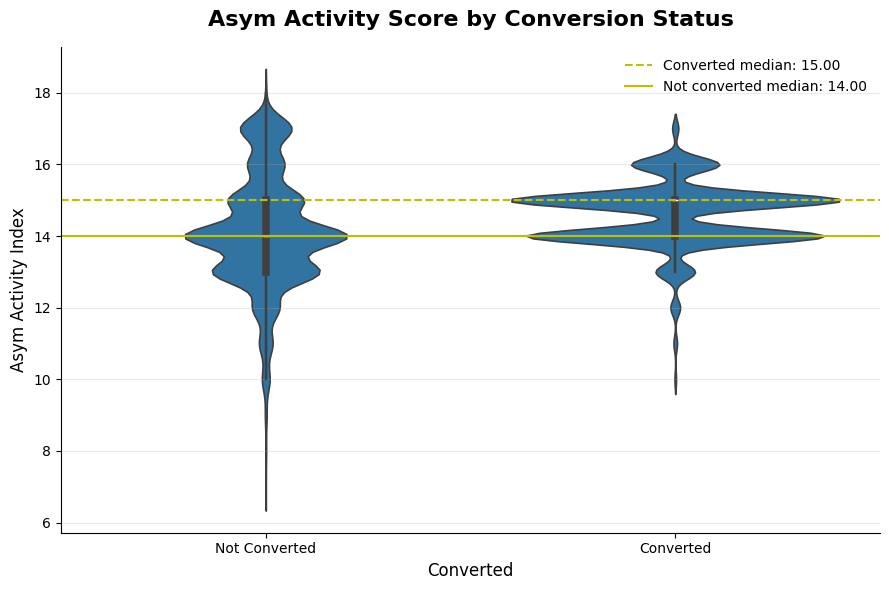

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

asym_activity_notna = df_explore[
    df_explore['asym_activity_score'].notna()
]

median_converted = asym_activity_notna.loc[
    asym_activity_notna['converted'] == 1,
    'asym_activity_score'
].median()

median_not_converted = asym_activity_notna.loc[
    asym_activity_notna['converted'] == 0,
    'asym_activity_score'
].median()

plt.figure(figsize=(9, 6))

ax = sns.violinplot(
    data=asym_activity_notna,
    x='converted',
    y='asym_activity_score',

    linewidth=1.2
)

# Median lines
plt.axhline(
    median_converted,
    linestyle='--',
    color='y',
    linewidth=1.5,

    label=f'Converted median: {median_converted:.2f}'
)

plt.axhline(
    median_not_converted,
    linestyle='-',
    color='y',
    linewidth=1.5,
    label=f'Not converted median: {median_not_converted:.2f}'
)

ax.set_title(
    'Asym Activity Score by Conversion Status',
    fontsize=16,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Converted', fontsize=12)
ax.set_ylabel('Asym Activity Index', fontsize=12)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Not Converted', 'Converted'])

ax.grid(axis='y', alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.legend(frameon=False)
plt.tight_layout()
plt.show()

### analyzing the same distribuiton but with fillna
imputing the null changes the distribution
and now it does not look much promising. The medians are exactly the same but we keep it any way. Furthermore non converted distribution becomes more concentrated at median.



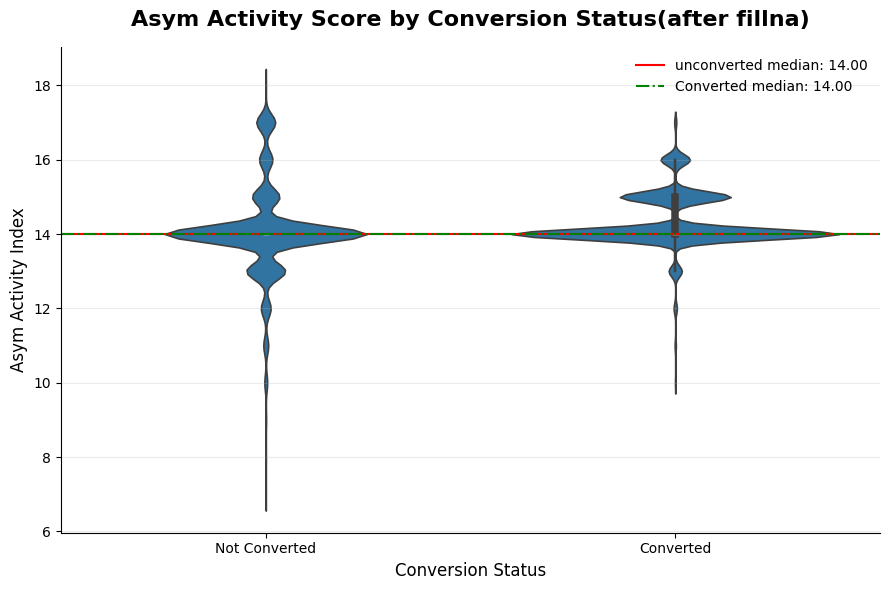

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

asym = df_explore.copy()

asym_activity_median = asym['asym_activity_score'].median()
asym['asym_activity_score']=asym['asym_activity_score'].fillna(asym_activity_median)

# Fill missing values only for non-converted leads
asym_activity_unconverted_median=asym.loc[
 asym['converted'] == 0,
  'asym_activity_score'
  ].median()


asym_activity_converted_median = asym.loc[
    asym['converted'] == 1,
    'asym_activity_score'
].median()

plt.figure(figsize=(9, 6))

ax = sns.violinplot(
    data=asym,
    x='converted',
    y='asym_activity_score',

    linewidth=1.2
)

# Overall median
ax.axhline(
    asym_activity_unconverted_median,
    linestyle='-',
    color='r',
    linewidth=1.5,
    label=f'unconverted median: {asym_activity_median:.2f}'
)

# Converted median
ax.axhline(
    asym_activity_converted_median,
    linestyle='-.',
    color='g',
    linewidth=1.5,
    label=f'Converted median: {asym_activity_converted_median:.2f}'
)

ax.set_title(
    'Asym Activity Score by Conversion Status(after fillna)',
    fontsize=16,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Conversion Status', fontsize=12)
ax.set_ylabel('Asym Activity Index', fontsize=12)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Not Converted', 'Converted'])

ax.grid(axis='y', alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

###checking if missingness of  is an indicator
As shown by the results missingness is clearly not an indicator as p value is greater than 0.05


In [ ]:
check_missing_usefulness(df_explore,'asym_activity_score'),chi2_test(df_explore,'asym_activity_score')

({'null_conversion_rate': np.float64(0.3961251862891207),
  'non_null conversion_rate': np.float64(0.376517215754273)},
 np.float64(0.08903068363619898))

###asym columns are missing exactly at the same rows

In [ ]:
(
(df_explore['asym_profile_score'].isna()==df_explore['asym_profile_index'].isna())&
(df_explore['asym_profile_index'].isna()==df_explore['asym_activity_index'].isna())&
(df_explore['asym_activity_index'].isna()==df_explore['asym_activity_score'])
).sum()

np.int64(0)

### imputing null columns

In [ ]:
null_cols=df_explore.columns[df_explore.isna().any()]
num_null_cols=df_explore[null_cols].select_dtypes(include='number').columns.tolist()
cat_null_cols=df_explore[null_cols].select_dtypes(include='object').columns.tolist()
num_null_cols,cat_null_cols

(['total_visits',
  'page_views_per_visit',
  'asym_activity_score',
  'asym_profile_score'],
 ['lead_source',
  'country',
  'specialization',
  'occupation',
  'course_reason',
  'city',
  'asym_activity_index',
  'asym_profile_index'])

In [ ]:

for col in num_null_cols:
  df_explore[col]=df_explore[col].fillna(df_explore[col].median())

for col in cat_null_cols:
  df_explore[col]=df_explore[col].fillna(df_explore[col].mode()[0])
df_explore.isna().sum().sum()


np.int64(0)

In [ ]:
0.998*7392
7392-7377

15

###dropping cols that have very little variation
dropping those columns in which 99.8% rows are the same value, ie there are only 0.2% rows(that is 15 rows) of other values

In [ ]:
variation_of_cols=df_explore.apply(lambda col:col.value_counts(normalize=True).iloc[0]*100)
low_var_cols=variation_of_cols.index[variation_of_cols>=99.8].tolist()
# dropping low var cols
df_explore=df_explore.drop(columns=low_var_cols)
# dropping id cols
df_explore=df_explore.drop(columns=['prospect_id','lead_number'])

In [ ]:
num_cols=df_explore.select_dtypes(include='number').columns.tolist()
num_cols


['converted',
 'total_visits',
 'time_on_website',
 'page_views_per_visit',
 'asym_activity_score',
 'asym_profile_score']

In [ ]:
cat_cols=df_explore.select_dtypes(include='object').columns.tolist()
cat_cols

['lead_origin',
 'lead_source',
 'do_not_email',
 'country',
 'specialization',
 'occupation',
 'city',
 'asym_activity_index',
 'asym_profile_index',
 'free_interview_copy']

### Analysis of numerical columns

**1**. time on website looks the most promising with the bulging median of converted distribution  lying inside the trailing part of unconverted distribution

**2**. total_visits for converted and non converted have almost the same distribution with converted one having relatively more outliers.Both have a very small middle 50% range. page_views_per_visit is the same but with a larger range.

**3**. asym_profile score distributions have essentially the same layout with unconverted distribution being more spikier than converted distribution (ie distribution changing more abruptly while in converted distribution the change is relativley smooth). It also does not seem to contribute much toward prediction. asym_activity_score has been analyzed.

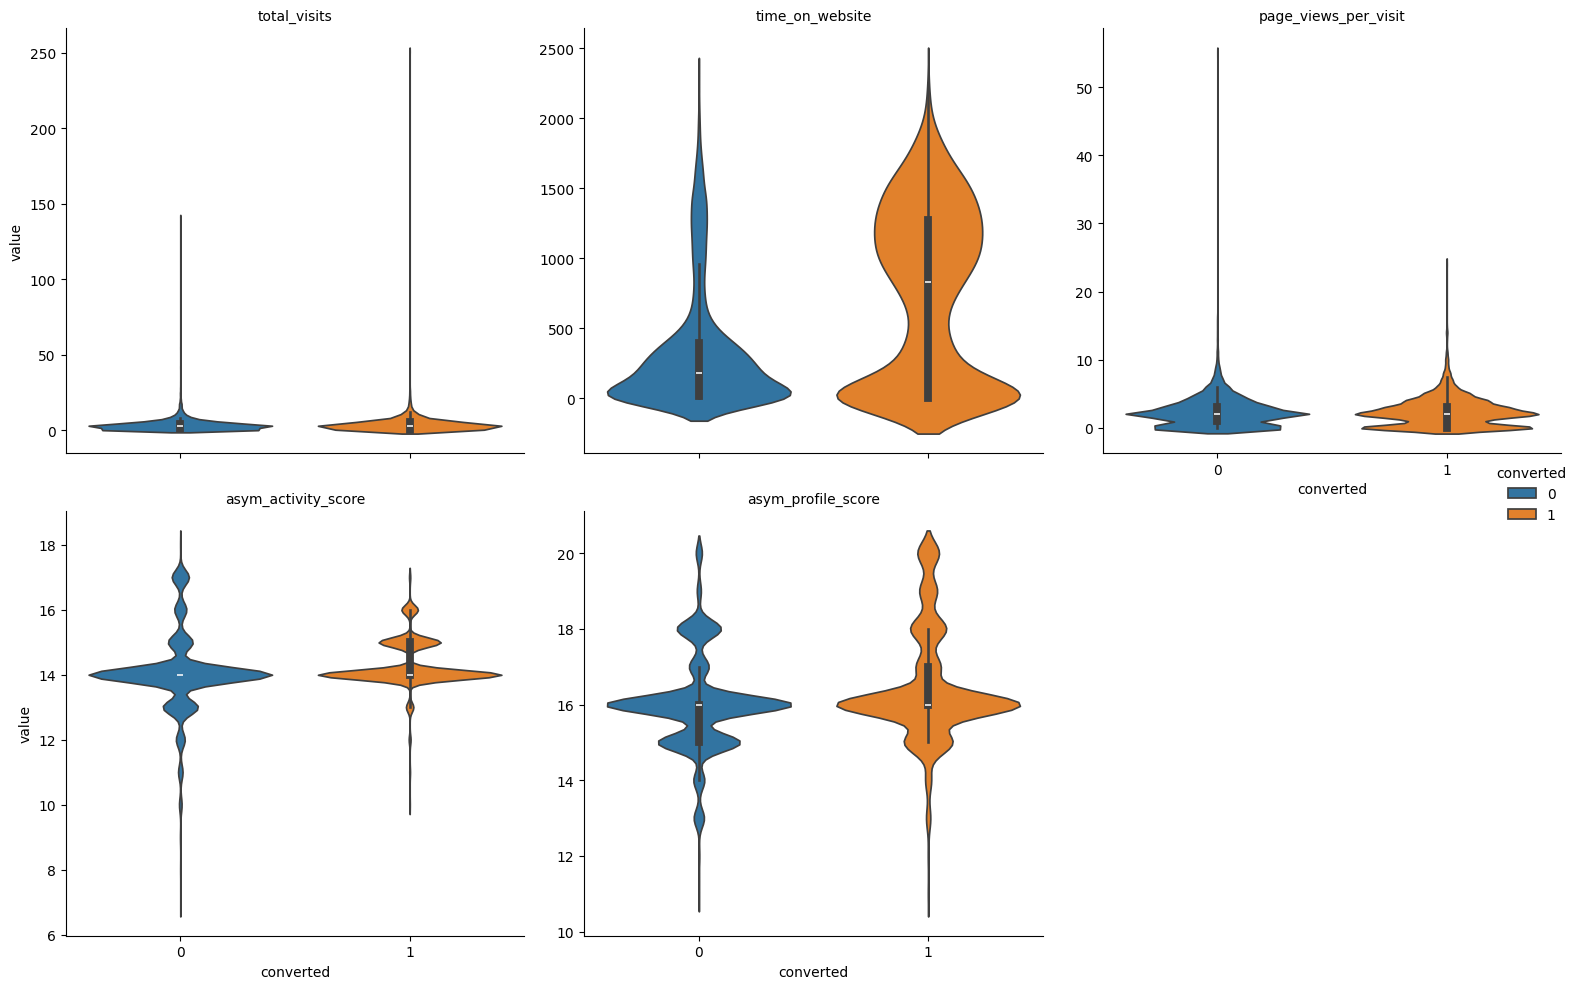

In [ ]:
plot_df = df_explore[num_cols].melt(
    id_vars='converted',
    var_name='feature',
    value_name='value'
)

g = sns.catplot(
    data=plot_df,
    x='converted',
    y='value',
    col='feature',
    col_wrap=3,
    kind='violin',
    hue='converted',
    # medianprops={'color': 'black', 'linewidth': 2},

    sharey=False
)

g.set_titles('{col_name}')
plt.tight_layout()
plt.show()

###Distribution of numerical columns
apart from asym_score and asym_profile_score all of them show right tailness

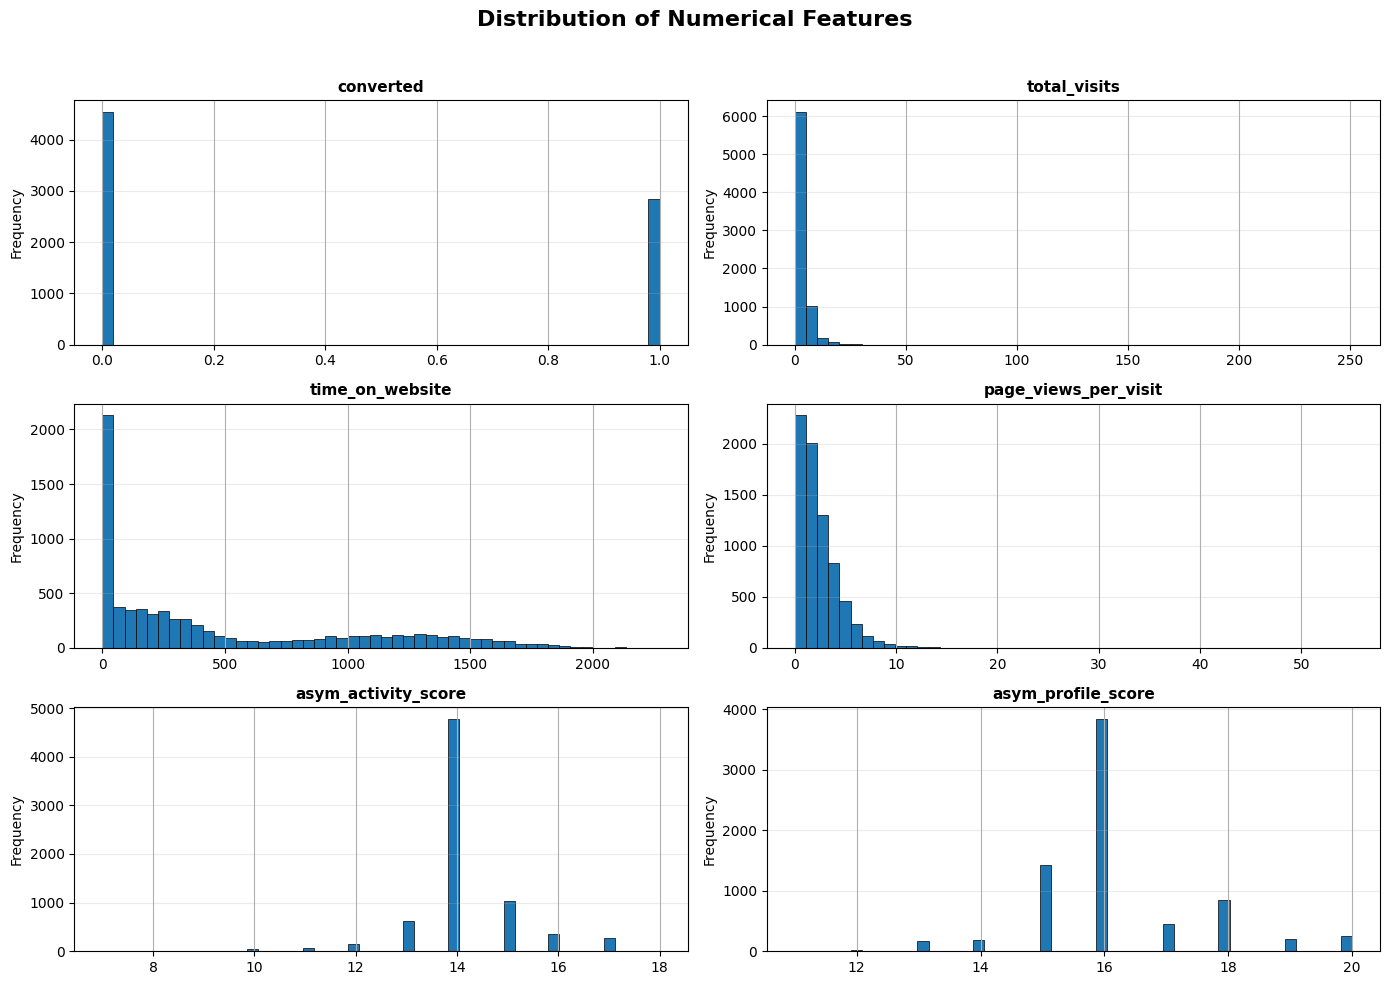

In [ ]:
import matplotlib.pyplot as plt

axes = (df_explore[num_cols]).hist(
    bins=50,
    figsize=(14, 10),
    edgecolor='black',
    linewidth=0.5
)

for ax in axes.flatten():
    ax.set_title(ax.get_title(), fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Frequency')
    ax.grid(axis='y', alpha=0.25)

plt.suptitle(
    'Distribution of Numerical Features',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

###do zero total visits or zero website time correlate with target?
It does not seem so. cramer'sv is 0.003 and conversion rates also dont seem to point to that direction

In [ ]:
df_explore['visited']=(df_explore['total_visits']!=0).astype(int)
df_explore['zero_time']=(df_explore['time_on_website']==0).astype(int)


In [ ]:
print(chi2_test(df_explore,'visited',for_null=False),cramer(df_explore,'converted','visited'))
chi2_test(df_explore,'zero_time',for_null=False),cramer(df_explore,'converted','zero_time')


0.003210255865134913 0.03460201699488749


(np.float64(0.004264388293546579), 0.033567278307614204)

In [ ]:
print(df_explore.groupby('visited')['converted'].mean())
df_explore.groupby('zero_time')['converted'].mean()

visited
0    0.415666
1    0.376041
Name: converted, dtype: float64


,converted
zero_time,
0,0.376308
1,0.414718


### Analysis of categorical columns
**lead origin and source**: provide good singal they can also be further binned

**do_not_mail**: is moderately good.
**country**: Denmark has 100% conversion rate but we have to check how many leads are of denmark before accepting this at face value. After  Denmark the conversion rate  drops to 50% round about and gradually reduces to 14% and then become 0% for some countries.
**occupation** sits neatly int three categories (90-100), (roundabout 50),(roundabout 30)

**pattern1**: leads coming from third party services(like *ClickToCall*,*WeLearn*,*Welingak Website*) almost always convert.

**pattern 2**: Bangladesh,Behrain,Oman,Hongkong,France have the same conversion rate 50%. There is something that is turning half of them away and half of them convert which is quite a pecuilar pattern.

**pattern 3**: Housewife and working professional have the higest rate of conversion. Student and unemployed the least. Perhaps the website can launch special program for students

**pattern 4**: As activity increases conversion rate increases. which chimes well with the prevous finding the time spent on website was a good predictor

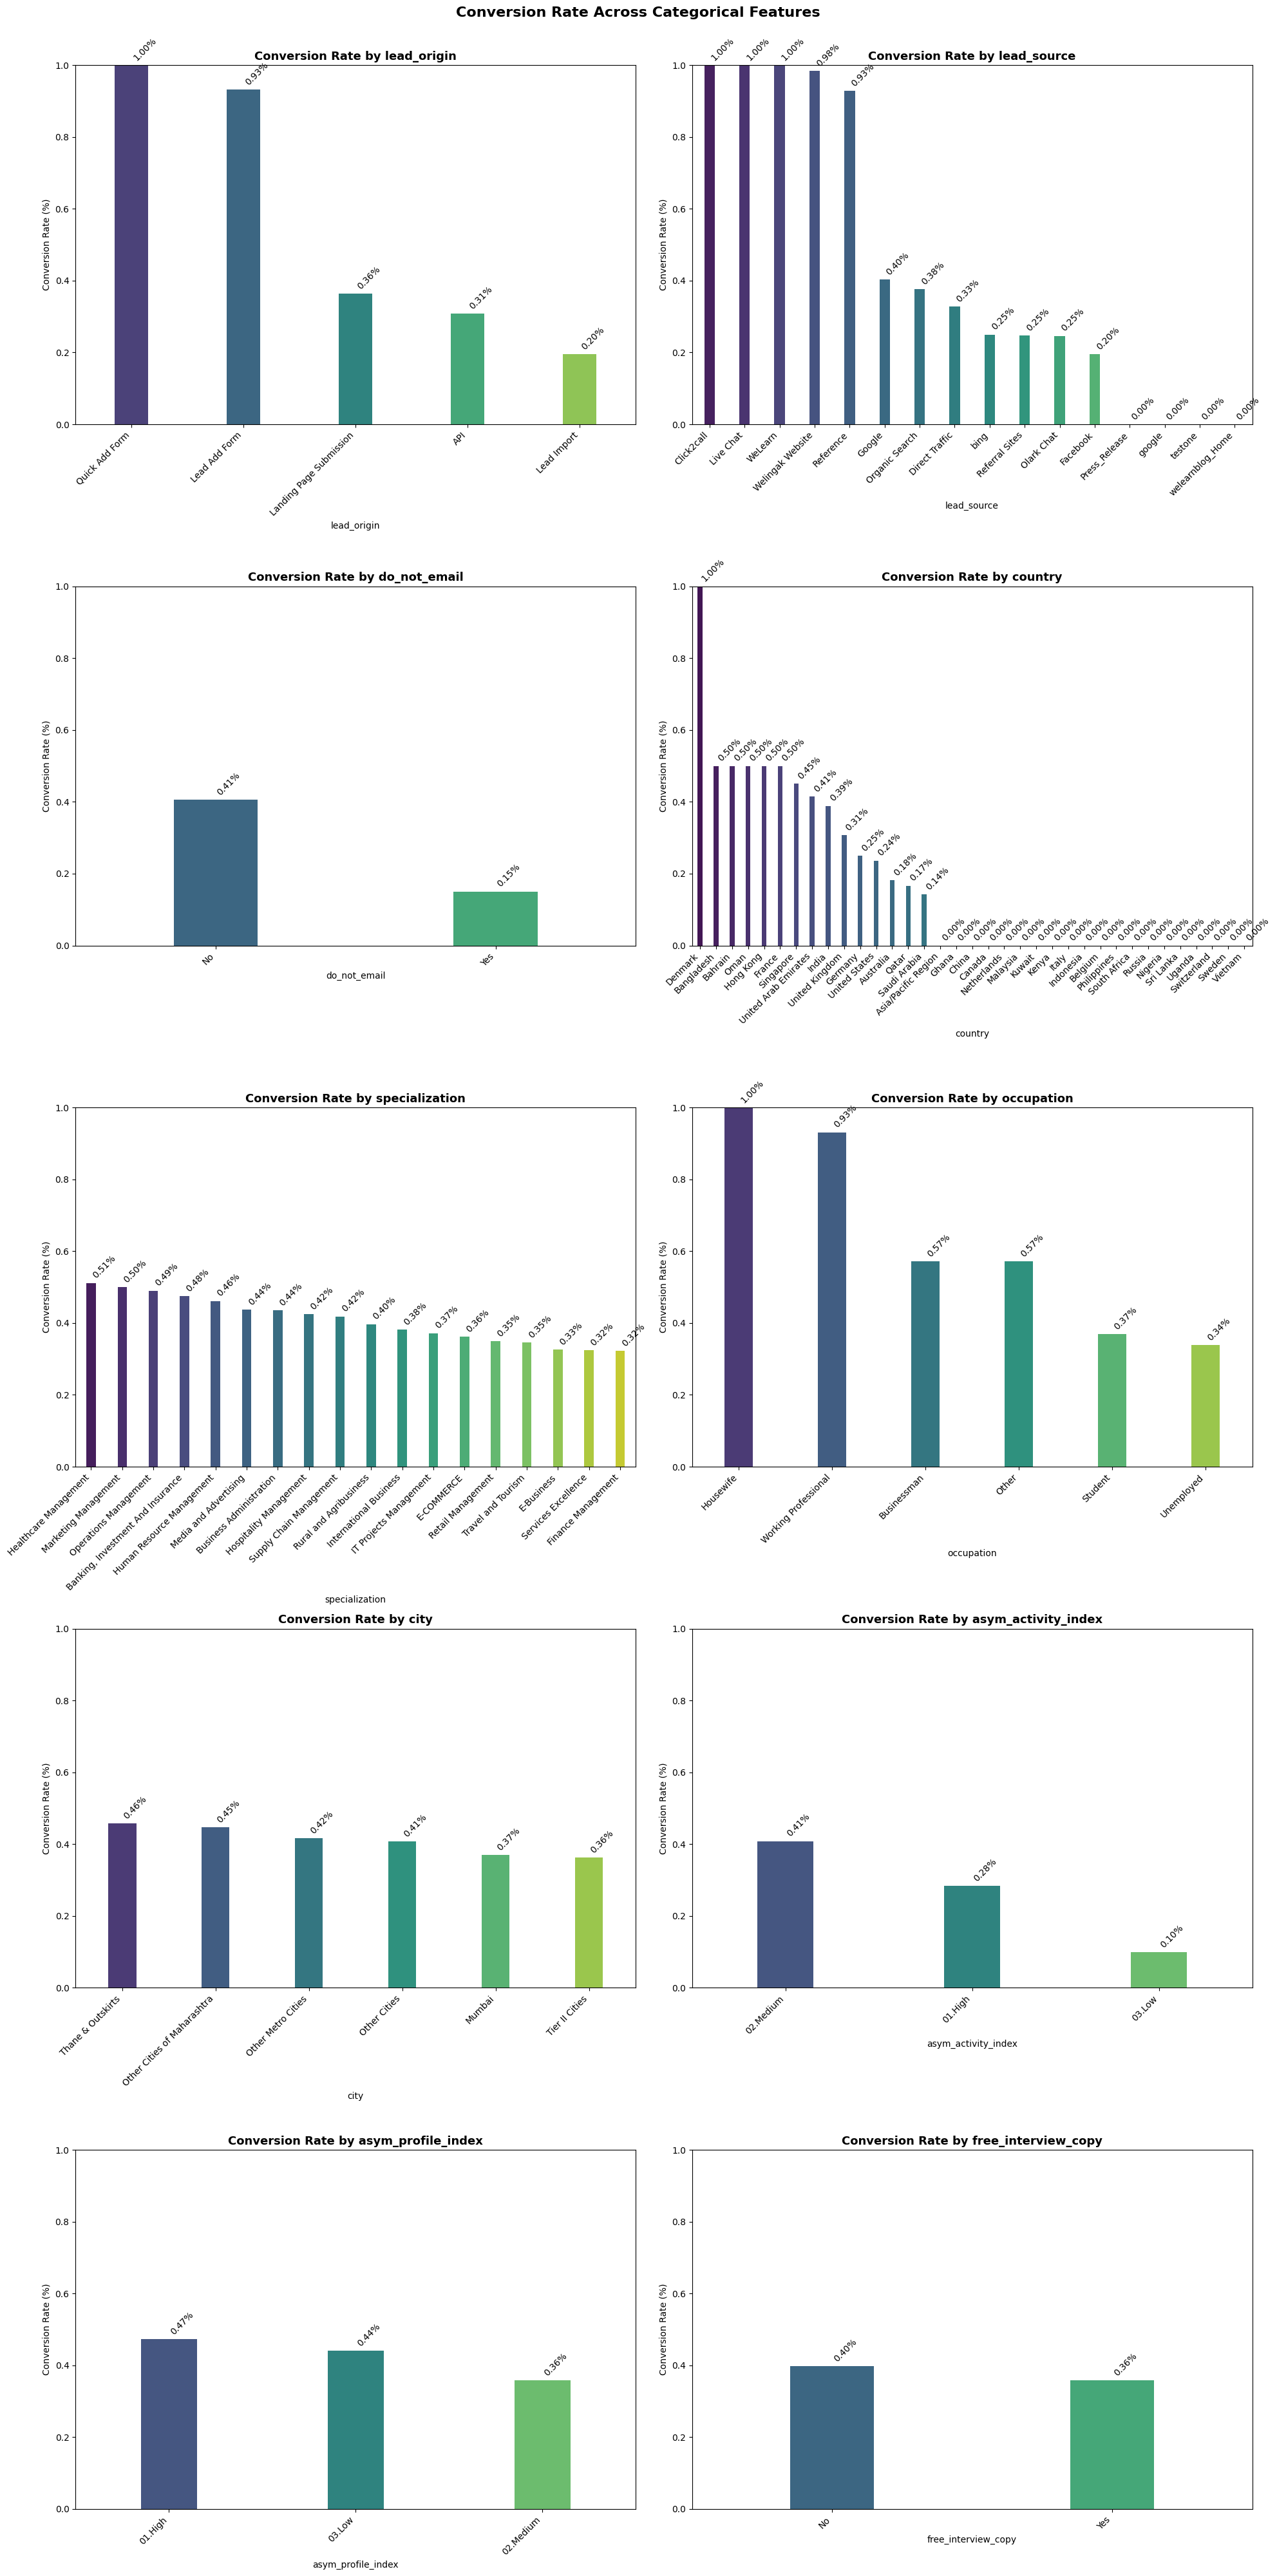

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

ncols = 2
nrows = math.ceil(len(cat_cols) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(20, 8 * nrows)
)

axes = axes.flatten()

for ax, col in zip(axes, cat_cols):

    conversion_rate = df_explore.groupby(col)['converted'].mean().sort_values(ascending=False).reset_index()

    sns.barplot(
        data=conversion_rate,
        x=col,
        y='converted',
        hue=col,
        palette='viridis',
        ax=ax,
        width=0.3,
    )

    ax.set_title(
        f'Conversion Rate by {col}',
        fontsize=13,
        fontweight='bold'
    )

    ax.set_xlabel(col)
    ax.set_ylabel('Conversion Rate (%)')

    ax.set_ylim(0, 1)

    for container in ax.containers:
        labels=ax.bar_label(
            container,
            fmt='%.2f%%',
            padding=3
        )
        for label in labels:
          label.set_rotation(45)
          label.set_ha('left')
    ax.tick_params(axis='x',rotation=45)
    plt.setp(ax.get_xticklabels(), ha='right')

for ax in axes[len(cat_cols):]:
    ax.remove()
fig.suptitle(
    'Conversion Rate Across Categorical Features',
    fontsize=16,
    fontweight='bold',
    y=0.999
)
plt.tight_layout()
plt.show()

col_bins_dictionary={
    'lead_origin':[0,0.21,0.38,1],
    'lead_source':[0,0.18,0.28,0.45,1],
    'country':[0,0.12,0.33,0.47,0.52,1],
    'occupation':[0,0.39,0.59,1]
}
col_labels_dictionary={
    'lead_origin':['low','medium','high'],
    'lead_source':['low','medium','good','high'],
    'country':['low','medium','good','better','high'],
    'occupation':['low','medium','high']
}



### combining categories

bin_col function combines categories of a categorical column to reduce the number of categories. The merging is done based on conversion rates of categories.It returns the binned column and a map that details the mapping between new and old values. We cannot use the conv_rate  method on test set columns to bin them(because that would be leakage) thats why a mapping from the train set columns is needed

for example mapping of new and old values of lead_source is as follows

'low': ['Lead Import'],

'medium': ['Landing Page Submission', 'API'],

'high': ['Lead Add Form', 'Quick Add Form']

In [ ]:
def bin_col(df,col,bins,labels):
  df=df.copy()
  # add conv_rate column for the given col
  df['conv_rate']= df.groupby(col)['converted'].transform('mean')
  # bin the conv_rate col
  df['binned']=pd.cut(df['conv_rate'],include_lowest=True,bins=bins,labels=labels)
  rates_col_map={}
  for label in labels:
    #extract the old values corresponding to the new value as a list
    cols=df[df['binned']==label][col].unique().tolist()
    rates_col_map[label]=cols
  return df['binned'],rates_col_map



labels = [
    'low',
    'mid',
    'good',
    'high'
]


###plotting the new column

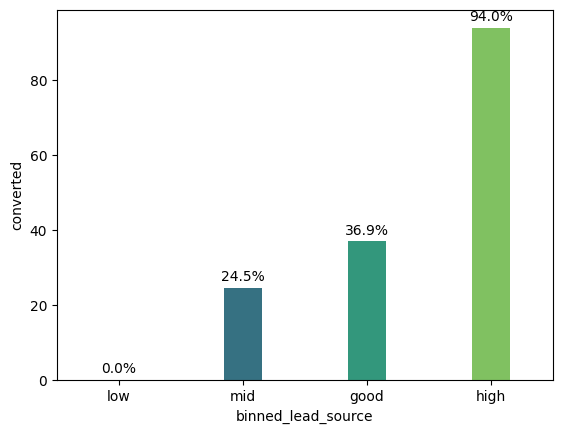

In [ ]:

df_explore['binned_lead_source'],col_map=bin_col(df_explore,'lead_source',bins=[0,0.18,0.29,0.90,1],labels=labels)

conversion_rate = df_explore.groupby('binned_lead_source',observed=False)['converted'].mean().sort_values(ascending=False).mul(100).reset_index()
fig,axis=plt.subplots(1,1)
sns.barplot(
    data=conversion_rate,
    x='binned_lead_source',
    y='converted',
    hue='binned_lead_source',
    ax=axis,
    palette='viridis',
    width=0.3,
)
for container in axis.containers:
  axis.bar_label(
              container,
              fmt='%.1f%%',
              padding=3
          )

plt.show()

In [ ]:
# moderately ocorrelated
chi2_test(df_explore,'binned_lead_source',for_null=False),cramer(df_explore,'converted','binned_lead_source')

(np.float64(1.147998787826023e-185), 0.3406897478512641)

In [ ]:
# generates the mappings between old and new values for the selected columns
def generate_binned_col_dictionary(df,cols,bins_of_cols,labels_of_cols):
  binned_col_dictionary={}
  for col in cols:
    # get mapping for a single categorical column
    _,col_map=bin_col(df,col,bins_of_cols[col],labels_of_cols[col])
    # add it to the dictionary
    binned_col_dictionary[col]=col_map
  return binned_col_dictionary

col_bins_dictionary={
    'lead_origin':[0,0.21,0.38,1],
    'lead_source':[0,0.18,0.28,0.45,1],
    'country':[0,0.12,0.33,0.47,0.52,1],
    'occupation':[0,0.39,0.59,1]
}
col_labels_dictionary={
    'lead_origin':['low','medium','high'],
    'lead_source':['low','medium','good','high'],
    'country':['low','medium','good','better','high'],
    'occupation':['low','medium','high']
}
cols_dictionary=generate_binned_col_dictionary(df_explore,['lead_origin','lead_source','country','occupation'],col_bins_dictionary,col_labels_dictionary)

In [ ]:
cols_dictionary

{'lead_origin': {'low': ['Lead Import'],
  'medium': ['Landing Page Submission', 'API'],
  'high': ['Lead Add Form', 'Quick Add Form']},
 'lead_source': {'low': ['google',
   'testone',
   'Press_Release',
   'welearnblog_Home'],
  'medium': ['Olark Chat', 'Facebook', 'Referral Sites', 'bing'],
  'good': ['Google', 'Organic Search', 'Direct Traffic'],
  'high': ['Welingak Website',
   'Reference',
   'Live Chat',
   'Click2call',
   'WeLearn']},
 'country': {'low': ['Kuwait',
   'Ghana',
   'Canada',
   'Sri Lanka',
   'South Africa',
   'Kenya',
   'Uganda',
   'China',
   'Russia',
   'Philippines',
   'Asia/Pacific Region',
   'Italy',
   'Belgium',
   'Switzerland',
   'Sweden',
   'Indonesia',
   'Malaysia',
   'Nigeria',
   'Netherlands',
   'Vietnam'],
  'medium': ['Qatar',
   'United Kingdom',
   'Australia',
   'United States',
   'Saudi Arabia',
   'Germany'],
  'good': ['India', 'United Arab Emirates', 'Singapore'],
  'better': ['Hong Kong', 'France', 'Bahrain', 'Oman', 'Ban

### Preprocessing
1. renaming the columns
2. converting 'Select' and 'unknown' vlaues to np.nan
3. imputing the numerical column,optionally taking their log and scaling them
4. imputing categorical columns one hot encoding them, also optionaly tried ordinal encoding the asym_index cols
5. Adding the new categorical columns with reduced number of values

**result**: Simple imputing ,standard scaling and one hot encoder worked the best

###method for preprocessing required before the sklearn pipeline

In [ ]:
def preparation(df,rename_map):
  df=df.copy()
  df=df.rename(columns=rename_map)
  df = df.replace(
    r'(?i)^(select|unknown)$',
    np.nan,
    regex=True
  )

  return df

In [ ]:
my_df=df_train.copy()
my_df=preparation(my_df,rename_map)

###Numerical and categorical columns

In [ ]:
num_cols_final=[
 'total_visits',
 'time_on_website',
 'page_views_per_visit',
 'asym_activity_score',
 'asym_profile_score']

cat_cols_final=[
'lead_origin',
 'lead_source',
 'do_not_email',
 'country',
 'specialization',
 'occupation',
 'city',
 'free_interview_copy']

ordinal_cols=[
  'asym_activity_index',
 'asym_profile_index'
 ]



### The Pipeline

In [ ]:
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer



def num_pipeline():
  return make_pipeline(
      SimpleImputer(strategy='median'),
      # FunctionTransformer(lambda X:np.log1p(X),feature_names_out='one-to-one'),
      StandardScaler()


  )



In [ ]:
def make_new_col(X,bin_mapping):
  X=np.array(X)
  conditions=[

      np.isin(X[:,0],values) for values in bin_mapping.values()
  ]
  choices=[
      key for key in bin_mapping.keys()
  ]
  return np.select(conditions,choices,default='ddd').reshape(-1,1)


def  new_col_transformer(bin_mapping):
  return make_pipeline(
      SimpleImputer(strategy='most_frequent'),
      FunctionTransformer(
          make_new_col,
          kw_args=dict(bin_mapping=bin_mapping),
          feature_names_out=lambda x,y :['binned']
          ),
      OneHotEncoder(sparse_output=False,handle_unknown='ignore')

  )



In [ ]:
def cat_pipeline():
  return make_pipeline(
      SimpleImputer(strategy='most_frequent'),
      OneHotEncoder(sparse_output=False,handle_unknown='ignore')

  )

def ordinal_pipeline():
  return  make_pipeline(
      SimpleImputer(strategy='most_frequent'),
      OrdinalEncoder(
      handle_unknown='use_encoded_value',
      unknown_value=-1
      )

  )


In [ ]:
preprocessing=ColumnTransformer(
    [
        ('num',num_pipeline(),num_cols_final),
        ('cat',cat_pipeline(),cat_cols_final+ordinal_cols),
        # ('ordinal',ordinal_pipeline(),ordinal_cols),
        # ('source',new_col_transformer(cols_dictionary['lead_source']),['lead_source']),
        # ('origin',new_col_transformer(cols_dictionary['lead_origin']),['lead_origin']),
        # ('country',new_col_transformer(cols_dictionary['country']),['country']),
        # ('occupation',new_col_transformer(cols_dictionary['occupation']),['occupation']),






    ]
)

## Testing the preprocessing pipeline

In [ ]:
data=preprocessing.fit_transform(my_df)
preprocessing.get_feature_names_out()


array(['num__total_visits', 'num__time_on_website',
       'num__page_views_per_visit', 'num__asym_activity_score',
       'num__asym_profile_score', 'cat__lead_origin_API',
       'cat__lead_origin_Landing Page Submission',
       'cat__lead_origin_Lead Add Form', 'cat__lead_origin_Lead Import',
       'cat__lead_origin_Quick Add Form', 'cat__lead_source_Click2call',
       'cat__lead_source_Direct Traffic', 'cat__lead_source_Facebook',
       'cat__lead_source_Google', 'cat__lead_source_Live Chat',
       'cat__lead_source_Olark Chat', 'cat__lead_source_Organic Search',
       'cat__lead_source_Press_Release', 'cat__lead_source_Reference',
       'cat__lead_source_Referral Sites', 'cat__lead_source_WeLearn',
       'cat__lead_source_Welingak Website', 'cat__lead_source_bing',
       'cat__lead_source_google', 'cat__lead_source_testone',
       'cat__lead_source_welearnblog_Home', 'cat__do_not_email_No',
       'cat__do_not_email_Yes', 'cat__country_Asia/Pacific Region',
       'cat__

####Helper Function

In [ ]:
from sklearn.model_selection import cross_val_predict

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# if train=False gets clean scores for each of the instances
# and calcualte metrics. Otherwise trains the model and get scores on
# on the same dataset. Useful for determining over fitting
def evaluate(name, model, X, y, method='predict_proba', threshold=0.5,train=False, cv=3):



    if train:
      model.fit(X,y)
      raw = model.predict_proba(X) if method == 'predict_proba' else model.decision_function(X)
    else:
      raw = cross_val_predict(model, X, y, cv=cv, method=method)
    scores = raw[:, 1] if method == 'predict_proba' else raw
    pred = scores >= threshold
    acc = accuracy_score(y, pred)
    prec_score=precision_score(y, pred, zero_division=0)
    rec_score=recall_score(y, pred)
    f1=f1_score(y, pred)
    ap, auc = average_precision_score(y, scores), roc_auc_score(y, scores)

    return {'name': name,
            'accuracy': acc,
            'ap': ap,
            'roc_auc': auc,
            'precision_score':prec_score,
            'recall_score':rec_score,
            'f1_score':f1,
            'confusion_matrix':confusion_matrix(y, pred)
            }

In [ ]:
X_train=my_df.drop('converted',axis=1)
y_train=my_df['converted'].copy()

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
dum_clf=DummyClassifier()
dum_clf.fit(X_train,y_train)
pred=dum_clf.predict(X_train)
accuracy_score(y_train,pred)

0.6145833333333334

###Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
logistic_pipeline=Pipeline(
    [
        ('preprocessing',preprocessing),
        ('model',LogisticRegression(verbose=2))
    ]
)

evaluate('logitic',logistic_pipeline,X_train,y_train,train=True)

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.5s finished


{'name': 'logitic',
 'accuracy': 0.8108766233766234,
 'ap': np.float64(0.8300343777433657),
 'roc_auc': np.float64(0.8683373964025516),
 'precision_score': 0.7991752577319587,
 'recall_score': 0.6802386802386803,
 'f1_score': 0.7349260523321957,
 'confusion_matrix': array([[4056,  487],
        [ 911, 1938]])}

In [ ]:
evaluate('logitic',logistic_pipeline,X_train,y_train,train=False,cv=4)

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.7s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.2s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.9s finished


{'name': 'logitic',
 'accuracy': 0.8068181818181818,
 'ap': np.float64(0.823569434368523),
 'roc_auc': np.float64(0.8626518551678138),
 'precision_score': 0.7934737711689385,
 'recall_score': 0.6742716742716742,
 'f1_score': 0.7290322580645161,
 'confusion_matrix': array([[4043,  500],
        [ 928, 1921]])}

###DecisionTreeClassifier


In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline(
    [
        ('preprocessing', preprocessing),
        ('model', DecisionTreeClassifier(random_state=42))
    ]
)


evaluate('decision_tree', decision_tree_pipeline, X_train, y_train, train=True)

{'name': 'decision_tree',
 'accuracy': 0.9675324675324676,
 'ap': np.float64(0.9915153997815723),
 'roc_auc': np.float64(0.9956575778719737),
 'precision_score': 0.9935679152478244,
 'recall_score': 0.9217269217269217,
 'f1_score': 0.956300072833212,
 'confusion_matrix': array([[4526,   17],
        [ 223, 2626]])}

In [ ]:

evaluate('decision_tree_cv', decision_tree_pipeline, X_train, y_train, train=False, cv=4)

{'name': 'decision_tree_cv',
 'accuracy': 0.761228354978355,
 'ap': np.float64(0.6145445166166449),
 'roc_auc': np.float64(0.7516222853004715),
 'precision_score': 0.7017870439314966,
 'recall_score': 0.6616356616356617,
 'f1_score': 0.6811201445347786,
 'confusion_matrix': array([[3742,  801],
        [ 964, 1885]])}

### RandomForestClassifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(
    [
        ('preprocessing', preprocessing),
        ('model', RandomForestClassifier(random_state=42))
    ]
)

print("Evaluating Random Forest Classifier (training data):")
evaluate('random_forest', random_forest_pipeline, X_train, y_train, train=True)

Evaluating Random Forest Classifier (training data):


{'name': 'random_forest',
 'accuracy': 0.9675324675324676,
 'ap': np.float64(0.9861077666534951),
 'roc_auc': np.float64(0.9906816862572971),
 'precision_score': 0.9946909366704588,
 'recall_score': 0.9206739206739206,
 'f1_score': 0.95625227852716,
 'confusion_matrix': array([[4529,   14],
        [ 226, 2623]])}

In [ ]:
print("Evaluating Random Forest Classifier (cross-validation):")
evaluate('random_forest_cv', random_forest_pipeline, X_train, y_train, train=False, cv=4)

Evaluating Random Forest Classifier (cross-validation):


{'name': 'random_forest_cv',
 'accuracy': 0.8084415584415584,
 'ap': np.float64(0.827997048432435),
 'roc_auc': np.float64(0.8722407397291836),
 'precision_score': 0.7837623762376238,
 'recall_score': 0.6946296946296946,
 'f1_score': 0.7365091179754373,
 'confusion_matrix': array([[3997,  546],
        [ 870, 1979]])}

### CatBoost Classifier

In [ ]:
!pip install catboost

In [ ]:
from catboost import CatBoostClassifier

catboost_pipeline = Pipeline(
    [
        ('preprocessing', preprocessing),
        ('model', CatBoostClassifier(random_state=42, verbose=0, )) # verbose=0 to suppress output during training
    ]
)

print("Evaluating CatBoost Classifier (training data):")
evaluate('catboost', catboost_pipeline, X_train, y_train, train=True)

Evaluating CatBoost Classifier (training data):


{'name': 'catboost',
 'accuracy': 0.8686417748917749,
 'ap': np.float64(0.9188806729643392),
 'roc_auc': np.float64(0.9380981560158317),
 'precision_score': 0.8594946401225115,
 'recall_score': 0.787995787995788,
 'f1_score': 0.8221937374107307,
 'confusion_matrix': array([[4176,  367],
        [ 604, 2245]])}

In [ ]:
print("Evaluating CatBoost Classifier (cross-validation):")
evaluate('catboost_cv', catboost_pipeline, X_train, y_train, train=False, cv=4)

Evaluating CatBoost Classifier (cross-validation):


{'name': 'catboost_cv',
 'accuracy': 0.8276515151515151,
 'ap': np.float64(0.8521777316527246),
 'roc_auc': np.float64(0.889889922797693),
 'precision_score': 0.7986348122866894,
 'recall_score': 0.7392067392067392,
 'f1_score': 0.7677725118483413,
 'confusion_matrix': array([[4012,  531],
        [ 743, 2106]])}

Model summary

| Model                  | Accuracy (CV) | AP (CV) | ROC AUC (CV) | Precision (CV) | Recall (CV) | F1 Score (CV) | Overfitting Indication (Train vs CV) |
|:-----------------------|:--------------|:--------|:-------------|:---------------|:------------|:--------------|:-------------------------------------|
| **Logistic Regression**| 0.8068        | 0.8236  | 0.8627       | 0.7935         | 0.6743      | 0.7290        | Slight drop, good generalization     |
| **Decision Tree**      | 0.7612        | 0.6145  | 0.7516       | 0.7018         | 0.6616      | 0.6811        | Significant drop, overfitting        |
| **Random Forest**      | 0.8084        | 0.8280  | 0.8722       | 0.7838         | 0.6946      | 0.7365        | Significant drop, overfitting        |
| **CatBoost**           | 0.8277        | 0.8522  | 0.8899       | 0.7986         | 0.7392      | 0.7678        | slight drop good generalization     |

**Model Assumptions and Limitations**

1. We are going to assume that the business has limited salesperson capacity and a large number of leads. In that case reducing wasted sale effort(false positives) and getting the top of the potential lead slice becomes important. So we will pick thresholds based on precision. As in this scenario we are optimizing for  the cost of false positive(wasted salesperson effort) we are gonna use average_precision to optimize the model
 in randomized search cv
 2. The model assumes that all the leads are independent thats why  no holdout validation is done. If we assume that there are 'groups' of related leads, then we would have to make sure that a model is never trained or tested on the same group so that we get  results that are valid across all groups

 3. The data available to us is for one period of time. To really evaluate the model precisely we should in principle train on one period and test on the other period's data which we cannot do.

 4. the probability scores do not represent real probablities ie leads which have 0.5 score are not going to be half as likely to be converted. In other words,no calibration is done.

 5. Another thing that I have assumed is the leakage column status of the web activity columns and asymmetrique columns. I have assumed that they describe activity up until the lead is acquired and not past it.


**Note**
although catboost gives good generalization on many metrics it overfits badly on average precision so we are going with logistic regression on this one



### Fine Tuning

As the dataset is large, to reduce training time I have chosen a small subset for fine tuning

In [ ]:
_,X_train_sample,_,y_train_sample=train_test_split(X_train,y_train,test_size=0.2,stratify=y_train,random_state=42)

In [ ]:
len(X_train_sample)

1479

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform,loguniform
logistic_reg_model=LogisticRegression(max_iter=500)
logistic_final_pipeline=Pipeline(
    [
        ('preprocessing',preprocessing),
        ('logistic_model',logistic_reg_model)
    ]
)
param_distrib=[
    {
     'logistic_model__penalty':['l1','l2'],
     'logistic_model__solver':['liblinear'],
     'logistic_model__intercept_scaling':[1,2,3,4],
     'logistic_model__C':loguniform(0.01,5)

    },

     {
     'logistic_model__penalty':['elasticnet'],
     'logistic_model__solver':['saga'],
     'logistic_model__intercept_scaling':[1,2],
     'logistic_model__C':loguniform(0.01,1),
      'logistic_model__l1_ratio':uniform(0,1)

    }

]

rand_search=RandomizedSearchCV(
    logistic_final_pipeline,
    param_distributions=param_distrib,
    n_iter=50,
    scoring='average_precision',
    refit=True,
    cv=4,
    verbose=2,
    random_state=42,
    return_train_score=True
    ,error_score='raise'
    )

rand_search.fit(X_train_sample,y_train_sample)

Fitting 4 folds for each of 50 candidates, totalling 200 fits
[CV] END logistic_model__C=1.4120355430626343, logistic_model__intercept_scaling=3, logistic_model__penalty=l1, logistic_model__solver=liblinear; total time=   0.2s
[CV] END logistic_model__C=1.4120355430626343, logistic_model__intercept_scaling=3, logistic_model__penalty=l1, logistic_model__solver=liblinear; total time=   0.2s
[CV] END logistic_model__C=1.4120355430626343, logistic_model__intercept_scaling=3, logistic_model__penalty=l1, logistic_model__solver=liblinear; total time=   0.1s
[CV] END logistic_model__C=1.4120355430626343, logistic_model__intercept_scaling=3, logistic_model__penalty=l1, logistic_model__solver=liblinear; total time=   0.1s
[CV] END logistic_model__C=0.15751320499779725, logistic_model__intercept_scaling=1, logistic_model__l1_ratio=0.44583275285359114, logistic_model__penalty=elasticnet, logistic_model__solver=saga; total time=   0.2s
[CV] END logistic_model__C=0.15751320499779725, logistic_model_

RandomizedSearchCV(cv=4, error_score='raise',
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('standardscaler',
                                                                                                StandardScaler())]),
                                                                               ['total_visits',
                                                                                'time_on_website',
                                                                                'page_views_per_visit',
                                                                                'asym_activity_score',
                                                                                'asym_profile_score']),
                                                                              ('cat',
                                                                               Pipeline(s...
                                        {'logistic_model__C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7dd19e406430>,
                                         'logistic_model__intercept_scaling': [1,
                                                                               2],
                                         'logistic_model__l1_ratio': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7dd19e4067b0>,
                                         'logistic_model__penalty': ['elasticnet'],
                                         'logistic_model__solver': ['saga']}],
                   random_state=42, return_train_score=True,
                   scoring='average_precision', verbose=2)

### best model

In [ ]:
rand_search.best_score_

np.float64(0.8296852004760518)

In [ ]:
rand_search.best_params_

{'logistic_model__C': np.float64(0.481130565736258),
 'logistic_model__intercept_scaling': 2,
 'logistic_model__penalty': 'l1',
 'logistic_model__solver': 'liblinear'}

In [ ]:
rand_search.best_index_

np.int64(29)

In [ ]:
from sklearn.base import clone
best_estimator=clone(rand_search.best_estimator_)

###ap_score is far larger than 0.38 meaning our model beats a random classifier

In [ ]:
y_train.value_counts(normalize=True)

,proportion
converted,
0,0.614583
1,0.385417


1. the model's average precision result is slightly lower for the whole train set

2. 0.45 looks like a good trade off precison is high and recall is not too low.


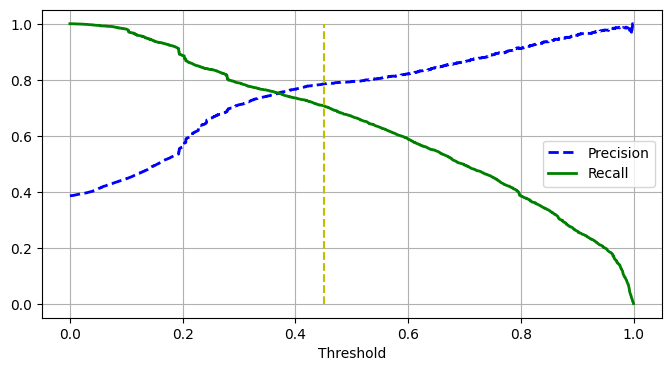

precision: 0.7852689010132502 recall:0.7072657072657073,average_precision:0.8236000942522582


In [ ]:
from sklearn.metrics import precision_recall_curve
raw = cross_val_predict(best_estimator, X_train, y_train, cv=4, method='predict_proba')
scores = raw[:, 1]
precisions,recalls,thresholds=precision_recall_curve(y_train,scores)
threshold=0.45
pred=(scores>threshold).astype(int)
pr_score=precision_score(y_train,pred)
avg_pre=average_precision_score(y_train,scores)
re_score=recall_score(y_train,pred)
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)



plt.grid()
plt.xlabel("Threshold")
plt.legend(loc="center right")

plt.plot([0.45,0.45],[0,1],'y--')


plt.show()
print(f'precision: {pr_score} recall:{re_score},average_precision:{avg_pre}')

### Testing

In [ ]:
best_estimator.fit(X_train,y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['total_visits',
                                                   'time_on_website',
                                                   'page_views_per_visit',
                                                   'asym_activity_score',
                                                   'asym_profile_score']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_fr...
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['lead_origin', 'lead_source',
                                                   'do_not_email', 'country',
                                                   'specialization',
                                                   'occupation', 'city',
                                                   'free_interview_copy',
                                                   'asym_activity_index',
                                                   'asym_profile_index'])])),
                ('logistic_model',
                 LogisticRegression(C=np.float64(0.481130565736258),
                                    intercept_scaling=2, max_iter=500,
                                    penalty='l1', solver='liblinear'))])

In [ ]:
df_test=preparation(df_test,rename_map)

In [ ]:
X_test,y_test=df_test.drop('converted',axis=1),df_test['converted'].copy()

**evaluation and interpretation**

our model has  overfitted the validation set a bit and has a precision of 0.75 and recall of 0.68 and average precison of 0.79 as opposed to the baseline of 0.38


1. The model's current results mean that 75% of the leads recommended by the model will be convertible  and 25%   will  not convert (with the current threshold).

2. The model will overall capture 68% of convertible leads(with the current threshold)

3. As expected false positve rate is less than false negative rate. The trade off maintained by the model is: less wasted effort but more missed potential leads

4. if you sort the leads in the order of decreasing score. and work on the first 50 94% percent of them (47) will convert

5. the fact that the model has slightly overfitted means that the actual numbers might be a little more worse than this.


In [ ]:
scores=best_estimator.predict_proba(X_test)[:,1]
final_pred=(scores>0.45).astype(int)
print(f'precision_score:{precision_score(y_test,final_pred)},recall_score:{recall_score(y_test,final_pred)},average_precision:{average_precision_score(y_test,scores)}')





precision_score:0.7558320373250389,recall_score:0.6825842696629213,average_precision:0.7908119794849483


### less false positve rate

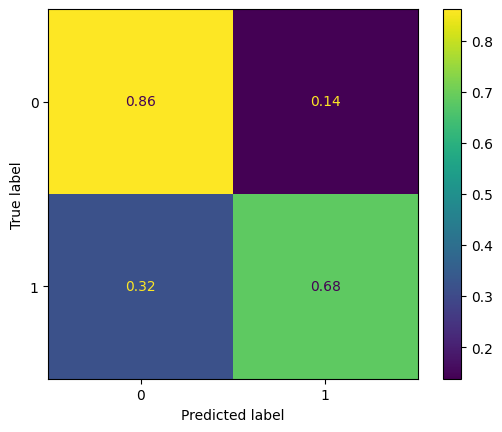

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test,final_pred,normalize='true')

###Precision@50

In [ ]:
test_copy=y_test.copy()
eval_df=pd.DataFrame({
    'actual':test_copy,
    'predicted_score':np.array(scores)
})
eval_df


,actual,predicted_score
683,1,0.662251
1931,1,0.379535
6950,0,0.248539
2996,0,0.102062
3902,0,0.119888
...,...,...
1290,1,0.992877
2174,0,0.541429
2418,1,0.957407
7757,0,0.102026


In [ ]:
eval_df=eval_df.sort_values(by='predicted_score',ascending=False)
eval_df[:50]['actual'].mean()

np.float64(0.92)

**looking at prediction**

the score of the prediction is 0.10. Althoug,score does not encode actual porbability the chance of this lead being converted is low as is confirmed by the test set. Moreover if we look at the histogram we see that it is one of many of leads that have least chance to convert. There is quite a blob from 0 to 0.3,suggesting there are many leads that share its fate. One could look at these leads and find a comon pattern between them to increase conversion rate.

In [ ]:
score_3=best_estimator.predict_proba(X_test.iloc[[3]])[:,1]
y_test.iloc[3],score_3

(np.int64(0), array([0.10206151]))

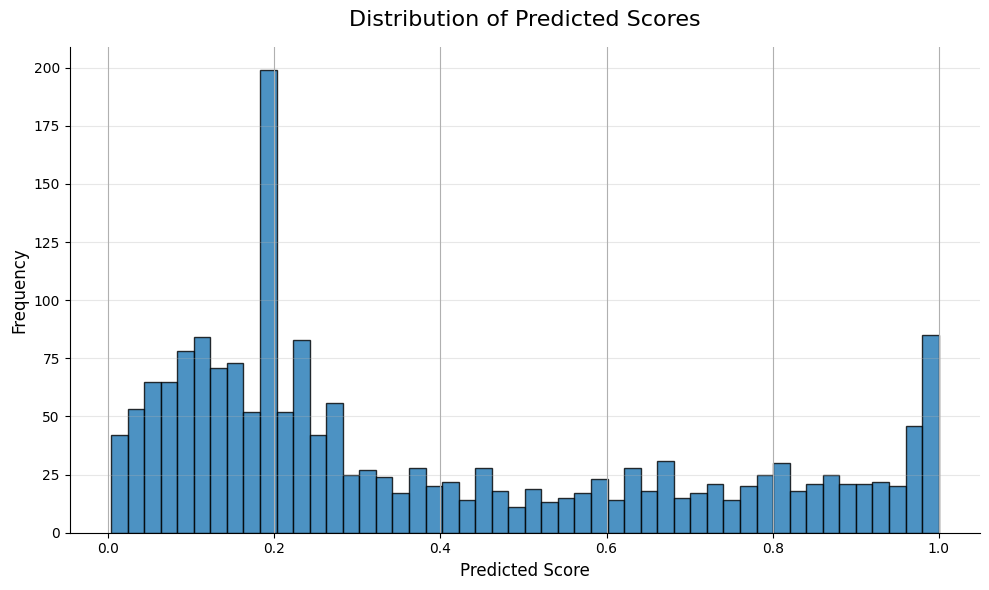

In [ ]:
import matplotlib.pyplot as plt

ax = eval_df['predicted_score'].hist(
    bins=50,
    figsize=(10, 6),
    edgecolor='black',
    alpha=0.8
)

ax.set_title('Distribution of Predicted Scores', fontsize=16, pad=15)
ax.set_xlabel('Predicted Score', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)

ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()